# Fortran-computed coverage heatmap

Reads `heatmap_pooled.csv`/`heatmap_grid.csv` written by
`monte_carlo_walk.f90` (run `./build/monte_carlo_walk` from this directory
first) and plots them the same way
`examples/python/monte_carlo_walk.ipynb` plots its own Python-computed
heatmap, for a direct visual comparison. The two should agree up to
ordinary Monte-Carlo seed noise (Fortran's own `RANDOM_NUMBER` stream vs.
NumPy's `default_rng` -- not a bit-for-bit match, see `monte_carlo_walk.f90`'s
header comment).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRAIN_VELOCITIES_MAX = 9319   # nominal max of the training grid, for reference (see examples/python/train_models.ipynb)


def load_heatmap(path):
    df = pd.read_csv(path)
    velocities = np.sort(df["velocity"].unique())
    angles = np.sort(df["angle"].unique())
    grid = df.pivot(index="velocity", columns="angle", values="mean_coverage").loc[velocities, angles].values
    return velocities, angles, grid


pooled_velocities, pooled_angles, pooled_mean = load_heatmap("heatmap_pooled.csv")
grid_velocities, grid_angles, grid_mean = load_heatmap("heatmap_grid.csv")
assert np.array_equal(pooled_velocities, grid_velocities) and np.array_equal(pooled_angles, grid_angles)
print(f"loaded {pooled_mean.shape[0]}x{pooled_mean.shape[1]} (velocity x angle) heatmaps")


loaded 11x9 (velocity x angle) heatmaps


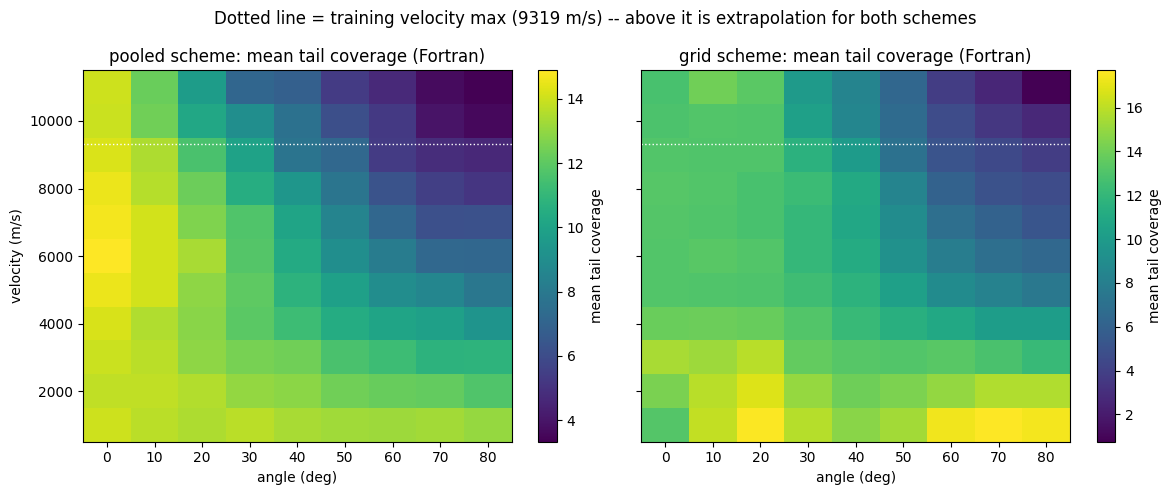

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, grid, title in zip(axes, [pooled_mean, grid_mean], ["pooled", "grid"]):
    im = ax.pcolormesh(pooled_angles, pooled_velocities, grid, shading="auto", cmap="viridis")
    ax.axhline(TRAIN_VELOCITIES_MAX, color="white", linestyle=":", linewidth=1)
    ax.set_xlabel("angle (deg)")
    ax.set_title(f"{title} scheme: mean tail coverage (Fortran)")
    fig.colorbar(im, ax=ax, label="mean tail coverage")
axes[0].set_ylabel("velocity (m/s)")
fig.suptitle("Dotted line = training velocity max (9319 m/s) -- above it is extrapolation for both schemes")
plt.tight_layout(); plt.show()
